# 01 · Análisis de sentimiento de reseñas (Reto 1)

**Objetivo de negocio:** clasificar automáticamente las reseñas de Nile Prime como positivas
o negativas para monitorizar la recepción del catálogo, y decidir qué modelo desplegar
equilibrando acierto y costo operativo.

**Objetivo técnico:** comparar un baseline trivial, tres modelos clásicos (TF-IDF + Regresión
Logística, LinearSVC, Naive Bayes) y un transformer preentrenado (DistilBERT-SST2), con
partición train / validación / test sin fuga, hiperparámetros por CV sobre train, selección del
modelo, calibración y umbral decididos en **validación**, y **una única** evaluación en test con
IC 95 % bootstrap. Incluye costo operativo, análisis de errores y ficha del modelo.

**Nota sobre las cifras:** las cifras citadas en el texto corresponden a la **ejecución
completa** (`full`). Con `NP_FAST=1` (5.000 reseñas, rejilla y bootstrap reducidos) varían y
valen las salidas de las celdas.

## Requisitos

- **Local:** Python ≥ 3.11 y `pip install -r requirements.txt` (o `python harness/init.py --install`, que crea el `.venv`).
- **Colab:** la celda de instalación de más abajo ejecuta `%pip install -q paquete==versión` **solo para lo que falte** (versión fijada). No se reinstalan `numpy`, `pandas`, `scikit-learn`, `matplotlib` ni `torch`: Colab ya los trae y cambiarlos obliga a reiniciar el entorno, lo que rompe «Ejecutar todo». Si no hay `data/raw`, la primera celda clona el repositorio público (o usa `NilePrime_AliGuerrero_codigo.zip` en `/content`).
- **Librerías de este notebook (versión de `requirements.txt`):** `pandas==2.3.3`, `numpy==2.3.5`, `scikit-learn==1.7.2`, `joblib==1.5.2`, `matplotlib==3.10.6`, `torch==2.14.1`, `transformers==5.19.0`.
- **Modelo externo:** el transformer se descarga solo de Hugging Face la primera vez: [distilbert-base-uncased-finetuned-sst-2-english](https://huggingface.co/distilbert/distilbert-base-uncased-finetuned-sst-2-english) (necesita internet).

In [1]:
# Entorno: Colab o local y raíz del proyecto sin rutas absolutas (la instalación va en la celda siguiente).
REPO_URL = "https://github.com/aliguerreroj/nile-prime-ia.git"  # repositorio público con código y datos
ZIP_NAME = "NilePrime_AliGuerrero_codigo.zip"  # alternativa sin GitHub: subirlo a /content

import os
import sys
from pathlib import Path

EN_COLAB = "google.colab" in sys.modules
FAST = os.environ.get("NP_FAST") == "1"
SEED = 42

# Raíz = primera carpeta (cwd o sus padres) que contiene data/raw.
RAIZ = next(
    (p for p in (Path.cwd(), *Path.cwd().parents) if (p / "data" / "raw").is_dir()),
    None,
)
if RAIZ is None and EN_COLAB:
    # Colab: (a) zip en /content, (b) si no hay zip, git clone del repositorio público.
    import subprocess
    import zipfile

    _base = Path("/content")

    def _buscar_raiz():
        """Rutas directas primero; rglob solo como último recurso (sin recorrer /content/drive)."""
        for _d in (_base / "nile-prime-ia", _base / "NilePrime_AliGuerrero_codigo", _base):
            if (_d / "data" / "raw").is_dir():
                return _d
        for _sub in sorted(_base.iterdir()):
            if _sub.is_dir() and _sub.name not in ("drive", "sample_data"):
                for _raw in sorted(_sub.rglob("raw")):
                    if _raw.parent.name == "data" and _raw.is_dir():
                        return _raw.parent.parent
        return None

    for _z in sorted(_base.glob("NilePrime*codigo*.zip")) or sorted(_base.glob("*.zip")):
        with zipfile.ZipFile(_z) as _f:
            if any("data/raw/" in n for n in _f.namelist()):
                _f.extractall(_base)
                break
    RAIZ = _buscar_raiz()
    if RAIZ is None:
        try:
            _git = subprocess.run(["git", "clone", "--depth", "1", REPO_URL], cwd=_base,
                                  check=False, capture_output=True, text=True)
            _err = (_git.stderr or _git.stdout or "").strip().splitlines()
        except OSError as _e:
            _err = [str(_e)]
        RAIZ = _buscar_raiz()
        if RAIZ is None:
            raise RuntimeError(
                "No se pudo obtener el proyecto en Colab. Opción 1: comprueba la conexión a "
                "internet y vuelve a ejecutar (se clona " + REPO_URL + "). Opción 2: sube "
                + ZIP_NAME + " a /content y vuelve a ejecutar. Último error de git: "
                + (_err[-1] if _err else "sin salida")
            )
if RAIZ is None:
    raise FileNotFoundError(
        "No se encuentra data/raw: ejecuta el notebook desde la carpeta del proyecto o una subcarpeta."
    )
if str(RAIZ) not in sys.path:
    sys.path.insert(0, str(RAIZ))

# Caché de Hugging Face: en local dentro del proyecto (.cache/, ignorada por git); en Colab, la
# de por defecto. Sin barras de progreso ni telemetría para que las salidas no tengan ruido.
if not EN_COLAB:
    os.environ.setdefault("HF_HOME", str(RAIZ / ".cache" / "huggingface"))
os.environ.setdefault("HF_HUB_DISABLE_PROGRESS_BARS", "1")
os.environ.setdefault("HF_HUB_DISABLE_TELEMETRY", "1")
os.environ.setdefault("HF_HUB_DISABLE_XET", "1")  # descarga HTTP clásica (más estable aquí)
os.environ.setdefault("HF_HUB_DISABLE_SYMLINKS_WARNING", "1")  # el aviso incluye rutas locales
os.environ.setdefault("TOKENIZERS_PARALLELISM", "false")

'false'

In [2]:
# Instalación de dependencias (solo Colab, solo lo que falte; en local no instala nada).
# Colab trae torch y scikit-learn; solo se instala transformers si falta.
import importlib.util

# paquete pip -> (módulo importable, versión fijada en requirements.txt)
_REQUISITOS = {"transformers": ("transformers", "5.19.0")}
_faltan = [f"{p}=={v}" for p, (m, v) in _REQUISITOS.items() if importlib.util.find_spec(m) is None]
if EN_COLAB and _faltan:
    for _spec in _faltan:
        # Equivalente a la magia:  %pip install -q transformers==5.19.0
        # (se usa run_line_magic porque jupytext no descomenta magias dentro de un bloque `if`).
        get_ipython().run_line_magic("pip", f"install -q {_spec}")  # noqa: F821
    print("Instalado:", ", ".join(_faltan))
else:
    print("Nada que instalar" + ("" if EN_COLAB else " (entorno local: usa requirements.txt)"))

Nada que instalar (entorno local: usa requirements.txt)


In [3]:
# Imports, semilla y configuración común.
import io
import json
import shutil
import textwrap
import time
import warnings
from contextlib import contextmanager

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
import torch
import transformers
from sklearn.base import clone
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.dummy import DummyClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import brier_score_loss, confusion_matrix
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import Pipeline
from sklearn.svm import LinearSVC
from transformers import AutoModelForSequenceClassification, AutoTokenizer

from src import data, evaluation as ev, plots

# Filtro selectivo: solo los avisos de depreciación de terceros (ruido sin efecto en resultados).
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=DeprecationWarning)
transformers.logging.set_verbosity_error()
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(min(16, os.cpu_count() or 1))
plots.set_style()
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 20)
MODO = "fast" if FAST else "full"
N_BOOT = 200 if FAST else 1000
print(f"Modo: {MODO} | SEED = {SEED} | Colab: {EN_COLAB} | bootstrap = {N_BOOT}")
print(f"sklearn {sklearn.__version__} | torch {torch.__version__} | "
      f"transformers {transformers.__version__} | CUDA: {torch.cuda.is_available()}")

TIEMPOS: dict[str, float] = {}  # segundos por sección (presupuesto: < 15 min en total)


@contextmanager
def seccion(nombre: str):
    """Mide el tiempo de pared de una sección y lo guarda en ``TIEMPOS``."""
    t0 = time.perf_counter()
    yield
    TIEMPOS[nombre] = round(time.perf_counter() - t0, 1)


def fmt(m: dict, d: int = 4) -> str:
    """Formatea ``{"valor", "ic95"}`` como ``0.9012 [0.8960, 0.9063]``."""
    lo, hi = m["ic95"]
    return f"{m['valor']:.{d}f} [{lo:.{d}f}, {hi:.{d}f}]"

Modo: full | SEED = 42 | Colab: False | bootstrap = 1000
sklearn 1.7.2 | torch 2.14.1+cpu | transformers 5.19.0 | CUDA: False


## 1. Datos, limpieza y partición sin fuga

**Qué:** cargar las reseñas con `sin_duplicados=True` y particionarlas en
train (70 %) / validación (10 %) / test (20 %), estratificadas por sentimiento.

**Diferencia con el enunciado:** el caso describe las reseñas «junto con las calificaciones
asociadas», pero el archivo solo trae el texto (`review`) y la etiqueta binaria `sentiment`:
no hay calificación numérica ni título de película, así que el problema es de clasificación
binaria y este módulo no se puede cruzar con el catálogo.

**Limpieza de texto (documentada).** `data.load_reviews` aplica `data.clean_html`: cada etiqueta
HTML (`<br />`, etc.) se sustituye por un espacio y se colapsan los espacios repetidos
(evita pegar palabras contiguas). No se aplican stemming, eliminación de *stopwords* ni
normalización de mayúsculas fuera de lo que hace el vectorizador (`lowercase=True`): las
negaciones y las *stopwords* ("not", "but") portan señal de polaridad, y los transformers
necesitan el texto casi intacto. **Deduplicación antes del split:** los duplicados se detectan
comparando el texto *ya limpio* (textos que solo difieren en `<br />` son la misma reseña) y se
eliminan antes de particionar; así ninguna reseña puede estar a la vez en train y en test.

**Diseño de la partición (resuelve «comparar modelos» frente a «test una sola vez»):**
hiperparámetros → CV sobre train; **selección del modelo, calibración y umbral → validación**;
test → una única evaluación al final, solo como estimación insesgada con IC. El vectorizador
TF-IDF vive dentro de un `Pipeline`, de modo que se ajusta únicamente con los datos de train (y
con los de cada fold dentro de la CV).

In [4]:
with seccion("1_datos"):
    bruto = pd.read_csv(data.find_csv("Rese*.csv"), encoding="utf-8")
    n_bruto = len(bruto)
    n_con_html = int(bruto["review"].str.contains(r"<[^>]+>", regex=True).sum())
    n_sin_html = len(data.clean_html(bruto["review"]).drop_duplicates())
    del bruto

    rev = data.load_reviews(sin_duplicados=True)
    N_TOTAL = len(rev)
    X_all = rev["review"].to_numpy()
    y_all = (rev["sentiment"] == "positive").astype(int).to_numpy()  # clase positiva = 1

    idx = np.arange(N_TOTAL)
    idx_tmp, idx_te = train_test_split(idx, test_size=0.20, stratify=y_all, random_state=SEED)
    idx_tr, idx_va = train_test_split(
        idx_tmp, test_size=0.125, stratify=y_all[idx_tmp], random_state=SEED
    )
    Xtr, ytr = X_all[idx_tr], y_all[idx_tr]
    Xva, yva = X_all[idx_va], y_all[idx_va]
    Xte, yte = X_all[idx_te], y_all[idx_te]

    # Comprobación de ausencia de fuga: ningún texto compartido entre particiones.
    assert not (set(Xtr) & set(Xte)) and not (set(Xtr) & set(Xva)) and not (set(Xva) & set(Xte))

print(f"Reseñas originales: {n_bruto:,} | con etiquetas HTML: {n_con_html:,}")
print(f"Duplicados eliminados tras limpiar el HTML: {n_bruto - n_sin_html:,} "
      f"(comparación sobre el texto limpio)")
print(f"Reseñas tras sin_duplicados=True: {N_TOTAL:,} "
      f"(positive {int(y_all.sum()):,} / negative {int((1 - y_all).sum()):,})")
print(f"Particiones: train {len(Xtr):,} | validación {len(Xva):,} | test {len(Xte):,}")
print(f"% positivas: train {ytr.mean():.3f} | val {yva.mean():.3f} | test {yte.mean():.3f}")
longitud = pd.Series([len(t.split()) for t in Xtr])
print("Longitud en palabras (train): "
      f"mediana {longitud.median():.0f} | p90 {longitud.quantile(.9):.0f} | "
      f"p99 {longitud.quantile(.99):.0f} | máx {longitud.max()}")

Reseñas originales: 50,000 | con etiquetas HTML: 29,202
Duplicados eliminados tras limpiar el HTML: 422 (comparación sobre el texto limpio)
Reseñas tras sin_duplicados=True: 49,578 (positive 24,882 / negative 24,696)
Particiones: train 34,704 | validación 4,958 | test 9,916
% positivas: train 0.502 | val 0.502 | test 0.502


Longitud en palabras (train): mediana 172 | p90 448 | p99 909 | máx 2459


**Conclusión técnica:** el corpus queda balanceado (~50/50) y sin duplicados cruzados entre
particiones (verificado con un `assert` sobre conjuntos de textos). El balance justifica
accuracy y F1 como métricas principales; el F1 se calcula sobre la clase positiva. La cola larga
de longitudes (p99 ≈ 900 palabras) es relevante para el transformer, limitado a 512 tokens.

**Implicación de negocio:** las cifras que se reporten no están infladas por reseñas repetidas.

## 2. Baseline trivial y modelos clásicos con CV sobre train

**Qué:** `DummyClassifier(strategy="stratified")` como referencia (predice al azar según la
prior; acc ≈ F1 ≈ 0,5) y tres `Pipeline(TfidfVectorizer, clasificador)`. Los hiperparámetros se
ajustan con `GridSearchCV` estratificado de 3 folds sobre **train**, con F1 como métrica.
*Nota:* el baseline estratificado se ajusta y evalúa con una sola semilla (`SEED`); como su
predicción es aleatoria, su accuracy fluctúa alrededor de 0,5 (desviación binomial ≈ 0,005 con n ≈ 9.900) según la semilla, sin
consecuencia para la comparación (los modelos reales lo superan por ≈ 0,4).

**Decisiones de diseño del TF-IDF:** `min_df=3` (descarta términos casi únicos y acota la
dimensión con bigramas), `sublinear_tf=True` (atenúa la frecuencia bruta en reseñas largas),
`dtype=float32` (mitad de memoria). Se cachea el vectorizador entre candidatos con la caché de
`Pipeline(memory=...)` (clave = parámetros + datos de entrada, de modo que no hay fuga entre
folds) para evitar reajustarlo por cada valor de `C`; el modelo final se reajusta **sin** caché
para medir un tiempo de entrenamiento honesto.

**Espacio de búsqueda** (FAST usa un subconjunto):

| Modelo | `ngram_range` | Hiperparámetro |
|---|---|---|
| Regresión Logística (L2, `lbfgs`) | {(1,1), (1,2)} | `C` ∈ {1, 4, 16, 64} |
| LinearSVC | {(1,1), (1,2)} | `C` ∈ {0,05, 0,2, 0,5, 1} |
| MultinomialNB | {(1,1), (1,2)} | `alpha` ∈ {0,03, 0,1, 0,3, 1} |

In [5]:
CV_FOLDS = 3
if FAST:
    GRIDS = {
        "Regresión Logística": {"clf__C": [1, 10]},
        "LinearSVC": {"clf__C": [0.1, 1.0]},
        "Naive Bayes": {"clf__alpha": [0.1, 1.0]},
    }
else:
    GRIDS = {
        "Regresión Logística": {"clf__C": [1, 4, 16, 64]},
        "LinearSVC": {"clf__C": [0.05, 0.2, 0.5, 1.0]},
        "Naive Bayes": {"clf__alpha": [0.03, 0.1, 0.3, 1.0]},
    }
for g in GRIDS.values():
    g["tfidf__ngram_range"] = [(1, 1), (1, 2)]

CLFS = {
    "Regresión Logística": lambda: LogisticRegression(max_iter=1000, random_state=SEED),
    "LinearSVC": lambda: LinearSVC(random_state=SEED),
    "Naive Bayes": lambda: MultinomialNB(),
}


def tfidf() -> TfidfVectorizer:
    """TF-IDF con las decisiones de diseño documentadas arriba."""
    return TfidfVectorizer(min_df=3, sublinear_tf=True, dtype=np.float32, lowercase=True)


def puntuacion(modelo, X) -> np.ndarray:
    """P(positiva) si el modelo da probabilidades; si no, la función de decisión."""
    if hasattr(modelo, "predict_proba"):
        return modelo.predict_proba(X)[:, 1]
    return modelo.decision_function(X)


DIR_CACHE_SK = RAIZ / ".cache" / "sk_memory"
shutil.rmtree(DIR_CACHE_SK, ignore_errors=True)
cv = StratifiedKFold(n_splits=CV_FOLDS, shuffle=True, random_state=SEED)

MODELOS: dict[str, dict] = {}
with seccion("2_clasicos_cv"):
    for nombre, mk in CLFS.items():
        t0 = time.perf_counter()
        pipe_cv = Pipeline(
            [("tfidf", tfidf()), ("clf", mk())], memory=joblib.Memory(DIR_CACHE_SK, verbose=0)
        )
        gs = GridSearchCV(
            pipe_cv, GRIDS[nombre], cv=cv, scoring="f1", n_jobs=-1, refit=False
        ).fit(Xtr, ytr)
        t_busqueda = time.perf_counter() - t0
        # Reajuste final sin caché: mide el tiempo de entrenamiento real (TF-IDF + clasificador).
        pipe = Pipeline([("tfidf", tfidf()), ("clf", mk())]).set_params(**gs.best_params_)
        t0 = time.perf_counter()
        pipe.fit(Xtr, ytr)
        MODELOS[nombre] = {
            "pipe": pipe,
            "mk": mk,
            "params": {k: (list(v) if isinstance(v, tuple) else v)
                       for k, v in gs.best_params_.items()},
            "f1_cv": float(gs.best_score_),
            "t_busqueda_s": t_busqueda,
            "t_entrena_s": time.perf_counter() - t0,
        }
        print(f"{nombre:20s} mejores = {MODELOS[nombre]['params']} | F1 CV = "
              f"{gs.best_score_:.4f} | búsqueda {t_busqueda:.0f} s | "
              f"reajuste {MODELOS[nombre]['t_entrena_s']:.0f} s")
    shutil.rmtree(DIR_CACHE_SK, ignore_errors=True)

    dummy = DummyClassifier(strategy="stratified", random_state=SEED).fit(Xtr, ytr)

Regresión Logística  mejores = {'clf__C': 16, 'tfidf__ngram_range': [1, 2]} | F1 CV = 0.9093 | búsqueda 46 s | reajuste 13 s


LinearSVC            mejores = {'clf__C': 0.5, 'tfidf__ngram_range': [1, 2]} | F1 CV = 0.9112 | búsqueda 13 s | reajuste 13 s


Naive Bayes          mejores = {'clf__alpha': 0.3, 'tfidf__ngram_range': [1, 2]} | F1 CV = 0.8865 | búsqueda 11 s | reajuste 11 s


**Conclusión técnica:** la CV sobre train fija `C`/`alpha` y el rango de n-gramas sin tocar
validación ni test. Resultado: los tres modelos prefieren (1,2)-gramas; `C` óptimo = 16 (LR) y
0,5 (SVC), ambos interiores a la rejilla, y `alpha` = 0,3 (NB). F1 en CV: LR 0,909, LinearSVC
0,911, NB 0,887. El rango de n-gramas **sí** está en el borde del espacio (no se probaron
trigramas): limitación declarada; no se amplió la rejilla para no consumir presupuesto ni
introducir más tuning.

**Implicación de negocio:** los modelos clásicos se entrenan en ~12 s (más la búsqueda, <1
min) con CPU corriente.

## 3. Costo operativo de los modelos clásicos y rendimiento en validación

**Qué:** medir, para cada modelo clásico, el tamaño serializado (`joblib` a memoria), la latencia
por reseña con lote de 1 (200 reseñas, una a una) y en lote (toda la validación), y las métricas
en **validación** con IC 95 % bootstrap. **Por qué:** la elección del modelo final (sección 5) se
toma aquí, sin consultar el test.

**Hardware de medición:** CPU de portátil/sobremesa sin GPU; los tiempos son indicativos y
dependen de la máquina (se registra `os.cpu_count()` en el JSON).

In [6]:
def tamano_mb(obj) -> float:
    """Tamaño en MB del objeto serializado con joblib (en memoria)."""
    buf = io.BytesIO()
    joblib.dump(obj, buf)
    return buf.getbuffer().nbytes / 1e6


def latencias_ms(modelo, X, n_uno: int = 200) -> tuple[float, float]:
    """(ms/reseña con lote=1, ms/reseña en lote) de ``predict`` del modelo."""
    t0 = time.perf_counter()
    for t in X[:n_uno]:
        modelo.predict([t])
    uno = (time.perf_counter() - t0) / n_uno * 1000
    t0 = time.perf_counter()
    modelo.predict(X)
    lote = (time.perf_counter() - t0) / len(X) * 1000
    return uno, lote


with seccion("3_validacion_clasicos"):
    VAL = {}
    for nombre, d in MODELOS.items():
        pipe = d["pipe"]
        d["pred_va"] = pipe.predict(Xva)
        d["score_va"] = puntuacion(pipe, Xva)
        d["ic_va"] = ev.bootstrap_ci(yva, d["pred_va"], N_BOOT, SEED)
        d["tamano_mb"] = tamano_mb(pipe)
        d["lat_uno_ms"], d["lat_lote_ms"] = latencias_ms(pipe, Xva)
    pred_dummy_va = dummy.predict(Xva)
    ic_dummy_va = ev.bootstrap_ci(yva, pred_dummy_va, N_BOOT, SEED)

filas = [{"modelo": "Baseline (Dummy estratificado)",
          "accuracy": fmt(ic_dummy_va["accuracy"]), "F1": fmt(ic_dummy_va["f1"])}]
for nombre, d in MODELOS.items():
    filas.append({"modelo": nombre, "accuracy": fmt(d["ic_va"]["accuracy"]),
                  "F1": fmt(d["ic_va"]["f1"])})
print(f"VALIDACIÓN (n = {len(yva):,}) — media [IC 95 % bootstrap, {N_BOOT} remuestreos]")
print(pd.DataFrame(filas).to_string(index=False))
print()
print(pd.DataFrame({
    n: {"entrenamiento (s)": d["t_entrena_s"], "búsqueda CV (s)": d["t_busqueda_s"],
        "latencia lote=1 (ms)": d["lat_uno_ms"], "latencia en lote (ms)": d["lat_lote_ms"],
        "tamaño (MB)": d["tamano_mb"]} for n, d in MODELOS.items()
}).T.to_string())

VALIDACIÓN (n = 4,958) — media [IC 95 % bootstrap, 1000 remuestreos]
                        modelo                accuracy                      F1
Baseline (Dummy estratificado) 0.5083 [0.4944, 0.5234] 0.5104 [0.4940, 0.5272]
           Regresión Logística 0.9125 [0.9046, 0.9203] 0.9134 [0.9047, 0.9214]
                     LinearSVC 0.9157 [0.9078, 0.9234] 0.9168 [0.9085, 0.9245]
                   Naive Bayes 0.8889 [0.8806, 0.8981] 0.8888 [0.8794, 0.8983]

                     entrenamiento (s)  búsqueda CV (s)  latencia lote=1 (ms)  latencia en lote (ms)  tamaño (MB)
Regresión Logística            13.1797          45.7828                0.6247                 0.2723      10.2173
LinearSVC                      12.6019          13.1315                0.6496                 0.2518      10.2171
Naive Bayes                    11.4441          11.4903                2.9939                 0.2611      18.3477


**Conclusión técnica:** en validación, LinearSVC (acc 0,916; F1 0,917), LR (0,913; 0,913) y NB
(0,889; 0,889) superan con holgura al baseline (≈ 0,51). Los IC de LR y LinearSVC se solapan casi
por completo, por lo que la decisión no debe basarse en la diferencia puntual sino en la prueba
pareada de la sección 5. Costo: ~11-17 s de entrenamiento, 0,2-0,4 ms/reseña en lote (0,6-1 ms con
lote 1; el NB sale peor con lote 1, 3-4 ms, por el overhead de su cadena de predicción) y 10-18 MB,
dominados por el vocabulario TF-IDF de bigramas y no por el clasificador.

**Implicación de negocio:** cualquiera de los clásicos clasifica una reseña en una fracción de
milisegundo, sin GPU.

## 4. Transformer preentrenado: DistilBERT-SST2 (muestra de validación)

**Qué:** [`distilbert-base-uncased-finetuned-sst-2-english`](https://huggingface.co/distilbert/distilbert-base-uncased-finetuned-sst-2-english),
modelo público de Hugging Face, en CPU, sin reentrenar, con
`truncation=True, max_length=512`, lotes de 16 ordenados por longitud (minimiza el relleno) y
`torch.inference_mode()`. Se evalúa sobre una muestra estratificada de **validación**
(500 reseñas; 40 en FAST) para poder incluirlo en la selección sin tocar el test. La muestra de
**test** (~1.000) se evalúa una sola vez en la sección 7.

**Riesgos conocidos:** (1) desajuste de dominio: el modelo se afinó con SST-2 (frases cortas de
reseñas de cine) y aquí las reseñas tienen mediana de ~170 palabras; (2) truncamiento a 512
tokens: se mide el porcentaje real de reseñas truncadas, que pierden su final (a menudo donde
está el veredicto); (3) el mapeo de etiquetas se lee de `config.id2label`
(`POSITIVE`/`NEGATIVE` → 1/0), no se supone.

In [7]:
def cargar_transformer(model_id: str, device: str = "cpu"):
    """Carga tokenizador y modelo y devuelve (tok, mod, índice de la clase POSITIVE)."""
    tok = AutoTokenizer.from_pretrained(model_id)
    mod = AutoModelForSequenceClassification.from_pretrained(model_id).eval().to(device)
    id2 = {int(k): str(v).upper() for k, v in mod.config.id2label.items()}
    pos = next(k for k, v in id2.items() if v == "POSITIVE")
    return tok, mod, pos


def inferir_transformer(tok, mod, pos, textos, device="cpu", lote=16, max_length=512):
    """P(positiva) por reseña y segundos de inferencia (tokenización incluida)."""
    textos = list(textos)
    orden = np.argsort([len(t) for t in textos])
    p = np.empty(len(textos))
    t0 = time.perf_counter()
    with torch.inference_mode():
        for i in range(0, len(textos), lote):
            ids = orden[i:i + lote]
            enc = tok([textos[j] for j in ids], truncation=True, max_length=max_length,
                      padding=True, return_tensors="pt").to(device)
            p[ids] = torch.softmax(mod(**enc).logits.float(), dim=-1)[:, pos].cpu().numpy()
    return p, time.perf_counter() - t0


def pct_truncadas(tok, textos, max_length=512) -> float:
    """% de reseñas cuya tokenización completa supera ``max_length`` tokens."""
    n_tok = np.array([len(i) for i in tok(list(textos), truncation=False)["input_ids"]])
    return float((n_tok > max_length).mean() * 100)


MODELO_DISTIL = "distilbert-base-uncased-finetuned-sst-2-english"
N_VA_TR = 40 if FAST else 500
N_TE_TR = 80 if FAST else 1000

with seccion("4_distilbert_carga"):
    tok_d, mod_d, pos_d = cargar_transformer(MODELO_DISTIL)
    N_PARAMS_D = sum(p.numel() for p in mod_d.parameters())

with seccion("4_distilbert_validacion"):
    # Muestras estratificadas (índices relativos a cada partición).
    sub_va, _ = train_test_split(np.arange(len(yva)), train_size=N_VA_TR, stratify=yva,
                                 random_state=SEED)
    sub_te, _ = train_test_split(np.arange(len(yte)), train_size=N_TE_TR, stratify=yte,
                                 random_state=SEED)
    p_d_va, seg_d_va = inferir_transformer(tok_d, mod_d, pos_d, Xva[sub_va])
    pred_d_va = (p_d_va >= 0.5).astype(int)  # umbral natural del softmax (sin ajustar)
    ic_d_va = ev.bootstrap_ci(yva[sub_va], pred_d_va, N_BOOT, SEED)
    trunc_va = pct_truncadas(tok_d, Xva[sub_va])

print(f"DistilBERT en la muestra de validación (n = {len(sub_va)}): "
      f"acc {fmt(ic_d_va['accuracy'])} | F1 {fmt(ic_d_va['f1'])}")
print(f"Truncadas a 512 tokens en esta muestra: {trunc_va:.1f} % | "
      f"parámetros: {N_PARAMS_D / 1e6:.1f} M | "
      f"inferencia: {seg_d_va / len(sub_va) * 1000:.0f} ms/reseña (lote 16, CPU)")
print(f"Tiempo de carga del modelo (con descarga la primera vez): "
      f"{TIEMPOS['4_distilbert_carga']:.0f} s")

DistilBERT en la muestra de validación (n = 500): acc 0.8880 [0.8600, 0.9140] | F1 0.8852 [0.8542, 0.9113]
Truncadas a 512 tokens en esta muestra: 10.4 % | parámetros: 67.0 M | inferencia: 60 ms/reseña (lote 16, CPU)
Tiempo de carga del modelo (con descarga la primera vez): 2 s


**Conclusión técnica:** DistilBERT obtiene en la muestra de validación (n = 500) accuracy 0,888
[0,860; 0,914] y F1 0,885 [0,854; 0,911], algo por debajo de los clásicos (IC anchos por el n
pequeño). Un 10,4 % de las reseñas supera los 512 tokens y se trunca (11,2 % en la muestra de
test): su final, donde suele estar el veredicto, no llega al modelo. La inferencia cuesta ~62
ms/reseña en CPU con lote 16 y 59-66 ms con lote 1 (50 reseñas sueltas: el lote 16 apenas lo favorece en CPU) y el modelo tiene 67 M de parámetros (~268 MB). El desajuste de
dominio (SST-2: frases cortas) y el truncamiento son las hipótesis principales del peor
resultado, no probadas aquí (no se hizo un experimento de ablación).

**Implicación de negocio:** un transformer listo para usar no mejora el resultado en las reseñas
largas de Nile Prime y cuesta del orden de 60-300 veces más tiempo por reseña que un modelo clásico (según se mida con lote 1 o con lote 16).

## 5. Selección del modelo final (en validación)

**Regla de decisión fijada de antemano:**
1. Entre los clásicos, se toma el de mayor F1 en validación y se mantienen como *candidatos* los
   que **no** son significativamente peores (bootstrap pareado, IC 95 % de la diferencia de F1
   que contiene 0).
2. Entre los candidatos se elige el de **menor latencia por reseña** (costo operativo) y, en
   empate, el de menor tamaño.
3. DistilBERT solo sustituiría al clásico elegido si fuera **significativamente mejor** (IC 95 %
   pareado de la diferencia de accuracy y F1 > 0) en la misma muestra de validación; si no hay
   diferencia significativa o es peor, se descarta por costo.

In [8]:
with seccion("5_seleccion"):
    mejor = max(MODELOS, key=lambda n: MODELOS[n]["ic_va"]["f1"]["valor"])
    candidatos = []
    filas = []
    for n, d in MODELOS.items():
        if n == mejor:
            candidatos.append(n)
            continue
        par = ev.bootstrap_pareado(yva, MODELOS[mejor]["pred_va"], d["pred_va"], N_BOOT, SEED)
        lo, hi = par["f1"]["ic95"]
        peor_sig = lo > 0  # el mejor es significativamente superior
        filas.append({"vs mejor": f"{mejor} - {n}", "dif. F1": par["f1"]["diferencia"],
                      "IC95 dif. F1": f"[{lo:.4f}, {hi:.4f}]",
                      "significativa": peor_sig})
        if not peor_sig:
            candidatos.append(n)
    FINAL = min(candidatos, key=lambda n: (MODELOS[n]["lat_lote_ms"], MODELOS[n]["tamano_mb"]))

    # Comparación pareada transformer vs clásico elegido en la MISMA muestra de validación.
    cls_sub = MODELOS[FINAL]["pred_va"][sub_va]
    par_d = ev.bootstrap_pareado(yva[sub_va], pred_d_va, cls_sub, N_BOOT, SEED)
    DISTIL_GANA = par_d["accuracy"]["ic95"][0] > 0 and par_d["f1"]["ic95"][0] > 0

print("Comparaciones pareadas entre clásicos (validación):")
print(pd.DataFrame(filas).to_string(index=False))
print(f"\nMejor F1 en validación: {mejor} | candidatos no peores: {candidatos}")
print(f"Elegido por menor latencia/tamaño: {FINAL}")
print(f"\nDistilBERT - {FINAL} en la misma muestra de validación (n = {len(sub_va)}):")
for m in ("accuracy", "f1"):
    print(f"  dif. {m}: {par_d[m]['diferencia']:+.4f}  IC95 "
          f"[{par_d[m]['ic95'][0]:+.4f}, {par_d[m]['ic95'][1]:+.4f}]")
print(f"DistilBERT significativamente mejor: {DISTIL_GANA}")
if DISTIL_GANA:
    print("AVISO: el transformer superaría al clásico; el resto del notebook asume un "
          "modelo clásico y habría que adaptarlo (no esperado con este dominio).")
modelo_final_nombre = FINAL

Comparaciones pareadas entre clásicos (validación):
                       vs mejor  dif. F1     IC95 dif. F1  significativa
LinearSVC - Regresión Logística   0.0034 [0.0007, 0.0062]           True
        LinearSVC - Naive Bayes   0.0279 [0.0200, 0.0353]           True

Mejor F1 en validación: LinearSVC | candidatos no peores: ['LinearSVC']
Elegido por menor latencia/tamaño: LinearSVC

DistilBERT - LinearSVC en la misma muestra de validación (n = 500):
  dif. accuracy: -0.0240  IC95 [-0.0560, +0.0060]
  dif. f1: -0.0253  IC95 [-0.0600, +0.0056]
DistilBERT significativamente mejor: False


**Conclusión técnica:** el modelo final es **LinearSVC** (se fija aquí, sin tocar test). Es el
mejor en F1 de validación y supera de forma significativa, aunque por muy poco, a la Regresión
Logística (dif. F1 = +0,0034, IC 95 % [0,0007; 0,0062]) y con claridad al Naive Bayes (+0,028).
La ventaja sobre LR es de ~0,3 puntos: estadísticamente detectable con n = 4.958 pero de
relevancia práctica marginal, por lo que LR habría sido una alternativa igualmente defendible.
DistilBERT frente a LinearSVC en la misma muestra de validación: dif. accuracy = −0,024 [−0,056;
+0,006], dif. F1 = −0,025 [−0,060; +0,006]; el IC contiene 0 (sin diferencia significativa; con
n = 500 la potencia es limitada) y, en cualquier caso, no es significativamente mejor, así que la
regla lo descarta.

**Integridad de la selección:** la regla anterior se fijó antes de calcular ninguna métrica de
test y se aplicó tal cual, **sin cambios a posteriori**: modelo, calibración y umbral quedan
cerrados en esta sección y en la 6. El test (sección 7) solo estima el rendimiento. Allí se
compara además LinearSVC con LR de forma pareada con fines descriptivos: los IC marginales de
ambos se solapan (accuracy 0,915 [0,910; 0,921] frente a 0,912 [0,906; 0,917]), pero la prueba
pareada sí detecta la diferencia (+0,0034 de accuracy, IC 95 % [+0,0015; +0,0056]; McNemar
exacto 67 frente a 33 desacuerdos, p = 0,0009). Es una diferencia estadísticamente detectable
y de magnitud marginal (~0,3 puntos), coherente con la observada en validación; no cambia la
decisión ni se usó para tomarla.

**Implicación de negocio:** se despliega el modelo más barato entre los que rinden al nivel del
mejor; el transformer no demuestra una mejora que justifique su costo.

## 6. Calibración y umbral de decisión (en validación)

**Calibración.** Se compara, por **Brier score en validación**, el modelo final sin calibrar
(si ofrece probabilidades) frente a `CalibratedClassifierCV` (`sigmoid` y `isotonic`, `cv=3`,
ajustado solo con train). Un `LinearSVC` no devuelve probabilidades, por lo que en ese caso solo
compiten las dos calibraciones.

**Umbral.** Nunca 0,5 por defecto: se barre el umbral sobre las probabilidades de **validación**
y se minimiza el **costo esperado** con una matriz de costos explícita.

*Criterio de costos (decisión de negocio, no estimada de los datos):* un **falso positivo**
(reseña negativa clasificada como positiva) es una queja enmascarada de un usuario en riesgo de
abandono; un **falso negativo** (positiva clasificada como negativa) solo genera una revisión
innecesaria. Por eso se fija que lo primero cuesta el doble: `C_FP = 2`, `C_FN = 1` (unidades
relativas); la razón 2:1 es un juicio de negocio y no una medición. Se muestra además la sensibilidad a razones de costo FP:FN de 1:1, 2:1, 5:1 y 1:2.

In [9]:
C_FP, C_FN = 2.0, 1.0
RAZONES = {"1:1": (1.0, 1.0), "2:1 (base)": (2.0, 1.0), "5:1": (5.0, 1.0), "1:2": (1.0, 2.0)}

with seccion("6_calibracion_umbral"):
    base_pipe = clone(MODELOS[FINAL]["pipe"])  # mismos hiperparámetros, sin ajustar
    cand_cal = {}
    if hasattr(MODELOS[FINAL]["pipe"], "predict_proba"):
        cand_cal["sin calibrar"] = MODELOS[FINAL]["pipe"]
    for met in ("sigmoid", "isotonic"):
        cand_cal[met] = CalibratedClassifierCV(clone(base_pipe), cv=3, method=met, n_jobs=3).fit(
            Xtr, ytr
        )
    brier_va = {k: brier_score_loss(yva, m.predict_proba(Xva)[:, 1]) for k, m in cand_cal.items()}
    CAL_ELEGIDA = min(brier_va, key=brier_va.get)
    modelo_prob = cand_cal[CAL_ELEGIDA]
    p_va = modelo_prob.predict_proba(Xva)[:, 1]

    umbrales = np.linspace(0.05, 0.95, 91)
    sel = ev.umbral_por_costo(yva, p_va, C_FP, C_FN, umbrales)
    UMBRAL = sel["umbral"]
    sensib = {}
    for etq, (cfp, cfn) in RAZONES.items():
        s = ev.umbral_por_costo(yva, p_va, cfp, cfn, umbrales)
        sensib[etq] = {"umbral": s["umbral"], "costo": s["costo"],
                       "costo_en_0_5": s["costo_en_0_5"]}

print("Brier en validación por versión del modelo final:")
for k, v in brier_va.items():
    print(f"  {k:13s} {v:.5f}" + ("   <- elegida" if k == CAL_ELEGIDA else ""))
print(f"\nUmbral óptimo (C_FP={C_FP:g}, C_FN={C_FN:g}) en validación: {UMBRAL:.2f} | "
      f"costo {sel['costo']:.4f} frente a {sel['costo_en_0_5']:.4f} con 0,5")
print("Sensibilidad del umbral a la razón de costos FP:FN (validación):")
print(pd.DataFrame(sensib).T.to_string())

Brier en validación por versión del modelo final:
  sigmoid       0.06366   <- elegida
  isotonic      0.06379

Umbral óptimo (C_FP=2, C_FN=1) en validación: 0.60 | costo 0.1228 frente a 0.1341 con 0,5
Sensibilidad del umbral a la razón de costos FP:FN (validación):
            umbral  costo  costo_en_0_5
1:1         0.4600 0.0849        0.0871
2:1 (base)  0.6000 0.1228        0.1341
5:1         0.8300 0.1801        0.2751
1:2         0.3700 0.1154        0.1273


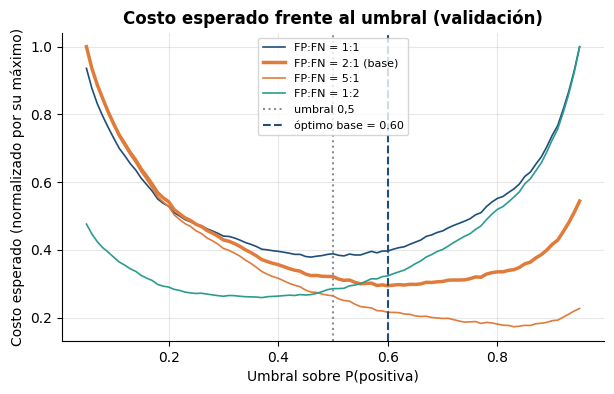

In [10]:
fig, ax = plt.subplots(figsize=(7, 4))
for etq, (cfp, cfn) in RAZONES.items():
    t, c = ev.curva_costo_umbral(yva, p_va, cfp, cfn, umbrales)
    ax.plot(t, c / c.max(), label=f"FP:FN = {etq}",
            lw=2.5 if "base" in etq else 1.2,
            color=plots.PALETA["enfasis"] if "base" in etq else None)
ax.axvline(0.5, color=plots.PALETA["neutro"], ls=":", label="umbral 0,5")
ax.axvline(UMBRAL, color=plots.PALETA["principal"], ls="--", label=f"óptimo base = {UMBRAL:.2f}")
ax.set_xlabel("Umbral sobre P(positiva)")
ax.set_ylabel("Costo esperado (normalizado por su máximo)")
ax.set_title("Costo esperado frente al umbral (validación)")
ax.legend(fontsize=8)
plots.save_fig(fig, "01_umbral_costo")
plt.show()

**Conclusión técnica:** el `LinearSVC` no tiene probabilidades nativas, así que se calibra con
Platt (`sigmoid`, Brier en validación 0,0637) frente a `isotonic` (0,0638): prácticamente
empatadas, y se elige la de menor Brier (la sigmoide es además más estable con pocos datos por
bin). El umbral óptimo con `C_FP:C_FN = 2:1` es **0,60** en validación (costo 0,1228 frente a
0,1341 con 0,5, −8,4 %): se exige más confianza para declarar «positiva». Con costos simétricos
el óptimo sería 0,46, cerca de 0,5, como cabe esperar con clases balanceadas y probabilidades
calibradas; con 5:1 sube a 0,83 y con 1:2 baja a 0,37. El valor depende por tanto del supuesto de
costos (que es una hipótesis, no un dato), más que del barrido fino. Limitación: el umbral se
elige en la misma validación que se usa para comparar el costo con 0,5, así que ese −8,4 % es
**optimista** (sesgo del mínimo sobre la muestra de elección); la cifra insesgada es la del test
(sección 7), donde el umbral ya no se toca.

**Implicación de negocio:** el umbral refleja que dejar pasar una queja cuesta más que revisar
una falsa alarma; si el negocio cambia esa razón de costos, basta con recalcular el umbral.

## 7. Evaluación única en test

**Qué:** a partir de aquí se toca el test **por primera y última vez**, ya con modelo,
calibración y umbral fijados en validación. Se evalúan todos los modelos con su regla de decisión
nativa sobre el test completo (clásicos y baseline), el modelo final con el umbral elegido y
DistilBERT sobre la muestra estratificada de ~1.000 reseñas de test.

**Comparación justa:** DistilBERT usa una submuestra, así que sus métricas no son comparables
1:1 con las de test completo. Para compararlo se calculan las métricas del modelo final sobre
**la misma muestra** y se usa una prueba **pareada** (McNemar exacto y bootstrap pareado de la
diferencia con IC 95 %). La decisión ya estaba tomada en validación; el test solo la confirma o
la desmiente, y se reporta cualquiera de los dos resultados.

**Modelo gigante ([`siebert/sentiment-roberta-large-english`](https://huggingface.co/siebert/sentiment-roberta-large-english)):** solo se ejecuta con GPU
(`torch.cuda.is_available()`); sin GPU se omite y queda registrado. Riesgo si se ejecutara: ese
modelo se afinó con conjuntos que incluyen reseñas de IMDB, por lo que una evaluación sobre estas
reseñas podría estar contaminada.

In [11]:
with seccion("7_test_clasicos"):
    TEST = {}  # nombre -> {"pred", "ic"}
    TEST["Baseline (Dummy estratificado)"] = {"pred": dummy.predict(Xte)}
    for n, d in MODELOS.items():
        TEST[n] = {"pred": d["pipe"].predict(Xte)}
    p_te = modelo_prob.predict_proba(Xte)[:, 1]
    pred_final_te = (p_te >= UMBRAL).astype(int)
    NOMBRE_FINAL = f"{FINAL} + umbral {UMBRAL:.2f} (modelo final)"
    TEST[NOMBRE_FINAL] = {"pred": pred_final_te}
    for n, d in TEST.items():
        d["ic"] = ev.bootstrap_ci(yte, d["pred"], N_BOOT, SEED)

with seccion("7_test_distilbert"):
    p_d_te, seg_d_te = inferir_transformer(tok_d, mod_d, pos_d, Xte[sub_te])
    pred_d_te = (p_d_te >= 0.5).astype(int)
    y_sub = yte[sub_te]
    ic_d_te = ev.bootstrap_ci(y_sub, pred_d_te, N_BOOT, SEED)
    trunc_te = pct_truncadas(tok_d, Xte[sub_te])
    LAT_D_MS = seg_d_te / len(sub_te) * 1000

filas = [{"modelo": n, "n": len(yte), "accuracy": fmt(d["ic"]["accuracy"]),
          "F1": fmt(d["ic"]["f1"])} for n, d in TEST.items()]
filas.append({"modelo": "DistilBERT-SST2 (muestra test)", "n": len(sub_te),
              "accuracy": fmt(ic_d_te["accuracy"]), "F1": fmt(ic_d_te["f1"])})
print(f"TEST — media [IC 95 % bootstrap, {N_BOOT} remuestreos], F1 de la clase positiva")
print(pd.DataFrame(filas).to_string(index=False))

# Baseline: ¿mejora significativa? (pareado, mismo test completo)
print("\nModelo final frente al baseline (pareado, test completo):")
par_b = ev.bootstrap_pareado(yte, pred_final_te, TEST["Baseline (Dummy estratificado)"]["pred"],
                             N_BOOT, SEED)
for m in ("accuracy", "f1"):
    print(f"  dif. {m}: {par_b[m]['diferencia']:+.4f}  IC95 "
          f"[{par_b[m]['ic95'][0]:+.4f}, {par_b[m]['ic95'][1]:+.4f}]")

# Comparación pareada DistilBERT vs. modelo final en la MISMA muestra de test
fin_sub = pred_final_te[sub_te]
ic_fin_sub = ev.bootstrap_ci(y_sub, fin_sub, N_BOOT, SEED)
par_t = ev.bootstrap_pareado(y_sub, pred_d_te, fin_sub, N_BOOT, SEED)
mcn = ev.mcnemar_exacto(y_sub, pred_d_te, fin_sub)
print(f"\nMisma muestra de test (n = {len(sub_te)}): modelo final acc {fmt(ic_fin_sub['accuracy'])} "
      f"| F1 {fmt(ic_fin_sub['f1'])}")
print(f"DistilBERT - modelo final: dif. accuracy {par_t['accuracy']['diferencia']:+.4f} "
      f"IC95 [{par_t['accuracy']['ic95'][0]:+.4f}, {par_t['accuracy']['ic95'][1]:+.4f}] | "
      f"dif. F1 {par_t['f1']['diferencia']:+.4f} "
      f"IC95 [{par_t['f1']['ic95'][0]:+.4f}, {par_t['f1']['ic95'][1]:+.4f}]")
print(f"McNemar exacto: DistilBERT acierta y final falla = {mcn['a_acierta_b_falla']}; "
      f"DistilBERT falla y final acierta = {mcn['a_falla_b_acierta']}; p = {mcn['p_valor']:.4g}")
print(f"Reseñas truncadas a 512 tokens en la muestra de test: {trunc_te:.1f} %")

# LR frente a LinearSVC en test (pareado, regla nativa de ambos). Es DESCRIPTIVO: la elección
# ya se hizo en validación con la regla de la sección 5 y este resultado no la modifica.
par_lr = ev.bootstrap_pareado(yte, TEST["LinearSVC"]["pred"],
                              TEST["Regresión Logística"]["pred"], N_BOOT, SEED)
mcn_lr = ev.mcnemar_exacto(yte, TEST["LinearSVC"]["pred"], TEST["Regresión Logística"]["pred"])
print(f"\nLinearSVC - Regresión Logística en test (n = {len(yte)}): "
      f"dif. accuracy {par_lr['accuracy']['diferencia']:+.4f} "
      f"IC95 [{par_lr['accuracy']['ic95'][0]:+.4f}, {par_lr['accuracy']['ic95'][1]:+.4f}] | "
      f"dif. F1 {par_lr['f1']['diferencia']:+.4f} "
      f"IC95 [{par_lr['f1']['ic95'][0]:+.4f}, {par_lr['f1']['ic95'][1]:+.4f}]")
print(f"McNemar exacto: SVC acierta y LR falla = {mcn_lr['a_acierta_b_falla']}; "
      f"SVC falla y LR acierta = {mcn_lr['a_falla_b_acierta']}; p = {mcn_lr['p_valor']:.4g}")

# ¿El test confirma la decisión tomada en validación?
orden_va = sorted(MODELOS, key=lambda n: -MODELOS[n]["ic_va"]["f1"]["valor"])
orden_te = sorted(MODELOS, key=lambda n: -TEST[n]["ic"]["f1"]["valor"])
print(f"\nOrden por F1 en validación: {orden_va}\nOrden por F1 en test:       {orden_te}")

TEST — media [IC 95 % bootstrap, 1000 remuestreos], F1 de la clase positiva
                                modelo    n                accuracy                      F1
        Baseline (Dummy estratificado) 9916 0.5026 [0.4926, 0.5127] 0.5083 [0.4962, 0.5193]
                   Regresión Logística 9916 0.9116 [0.9062, 0.9170] 0.9128 [0.9072, 0.9183]
                             LinearSVC 9916 0.9150 [0.9098, 0.9206] 0.9162 [0.9110, 0.9220]
                           Naive Bayes 9916 0.8952 [0.8895, 0.9011] 0.8957 [0.8898, 0.9017]
LinearSVC + umbral 0.60 (modelo final) 9916 0.9096 [0.9042, 0.9152] 0.9083 [0.9026, 0.9141]
        DistilBERT-SST2 (muestra test) 1000 0.8960 [0.8770, 0.9140] 0.8923 [0.8716, 0.9126]

Modelo final frente al baseline (pareado, test completo):
  dif. accuracy: +0.4070  IC95 [+0.3959, +0.4184]
  dif. f1: +0.4000  IC95 [+0.3877, +0.4134]



Misma muestra de test (n = 1000): modelo final acc 0.9110 [0.8920, 0.9290] | F1 0.9093 [0.8889, 0.9283]
DistilBERT - modelo final: dif. accuracy -0.0150 IC95 [-0.0360, +0.0060] | dif. F1 -0.0169 IC95 [-0.0393, +0.0055]
McNemar exacto: DistilBERT acierta y final falla = 51; DistilBERT falla y final acierta = 66; p = 0.1953
Reseñas truncadas a 512 tokens en la muestra de test: 11.2 %

LinearSVC - Regresión Logística en test (n = 9916): dif. accuracy +0.0034 IC95 [+0.0015, +0.0056] | dif. F1 +0.0034 IC95 [+0.0016, +0.0055]
McNemar exacto: SVC acierta y LR falla = 67; SVC falla y LR acierta = 33; p = 0.0008737

Orden por F1 en validación: ['LinearSVC', 'Regresión Logística', 'Naive Bayes']
Orden por F1 en test:       ['LinearSVC', 'Regresión Logística', 'Naive Bayes']


In [12]:
# Modelo grande (siebert/roberta-large): solo con GPU. Sin GPU se omite SIN error.
MODELO_GRANDE = "siebert/sentiment-roberta-large-english"
if torch.cuda.is_available():
    with seccion("7_roberta_large"):
        tok_g, mod_g, pos_g = cargar_transformer(MODELO_GRANDE, device="cuda")
        p_g, seg_g = inferir_transformer(tok_g, mod_g, pos_g, Xte[sub_te], device="cuda")
        ic_g = ev.bootstrap_ci(y_sub, (p_g >= 0.5).astype(int), N_BOOT, SEED)
        INFO_GRANDE = {"ejecutado": True, "n": int(len(sub_te)),
                       "accuracy": ic_g["accuracy"], "f1": ic_g["f1"],
                       "latencia_ms": seg_g / len(sub_te) * 1000,
                       "aviso": "posible contaminación: afinado con conjuntos que incluyen IMDB"}
        print("RoBERTa-large (GPU):", fmt(ic_g["accuracy"]), fmt(ic_g["f1"]))
else:
    INFO_GRANDE = {"ejecutado": False,
                   "motivo": "sin GPU (torch.cuda.is_available() es False); el modelo "
                             "(~355 M de parámetros) es inviable en CPU dentro del presupuesto"}
    print(f"{MODELO_GRANDE}: OMITIDO. Motivo: {INFO_GRANDE['motivo']}.")

siebert/sentiment-roberta-large-english: OMITIDO. Motivo: sin GPU (torch.cuda.is_available() es False); el modelo (~355 M de parámetros) es inviable en CPU dentro del presupuesto.


**Conclusión técnica:** el test **confirma** la decisión tomada en validación: el orden por F1
es idéntico (LinearSVC > Regresión Logística > Naive Bayes). En test completo (n = 9.916),
LinearSVC con su regla nativa alcanza accuracy 0,915 [0,910; 0,921] y F1 0,916 [0,911; 0,922];
LR 0,912 [0,906; 0,917] / 0,913; NB 0,895 / 0,896; el baseline 0,503 / 0,508. LinearSVC − LR
(pareado, descriptivo): +0,0034 de accuracy [+0,0015; +0,0056] y de F1 [+0,0016; +0,0055],
McNemar p = 0,0009: detectable pero marginal, pese a que los IC marginales se solapan. El **baseline LR
cumple la meta ≥ 0,89** (acc 0,912, F1 0,913). El modelo final (LinearSVC calibrado + umbral
0,60) obtiene accuracy 0,910 [0,904; 0,915] y F1 0,908 [0,903; 0,914]: es algo más bajo que con
la regla nativa **por diseño**, porque el umbral minimiza el costo FP/FN y no el error total (se
sacrifica ~0,5 puntos de accuracy y recall de la clase positiva a cambio de menos falsos
positivos). Mejora sobre el baseline: +0,407 en accuracy [0,396; 0,418]. DistilBERT, en una
muestra de 1.000 reseñas de test: accuracy 0,896 [0,877; 0,914], F1 0,892 [0,872; 0,913]; el modelo
final en esa misma muestra, 0,911 / 0,909. Diferencia pareada DistilBERT − final: accuracy −0,015
[−0,036; +0,006], F1 −0,017 [−0,039; +0,006]; McNemar exacto 51 frente a 66 desacuerdos,
p = 0,195: **sin diferencia significativa**. Es decir, no se puede afirmar que el transformer sea
peor ni mejor, aunque la estimación puntual favorece al modelo clásico y este es ~100 veces más
rápido (sección 9).

**Implicación de negocio:** el modelo elegido en validación se confirma en datos nunca usados
para decidir, con ~0,5 puntos de margen de error en el acierto.

## 8. Matriz de confusión, calibración en test y figuras de comparación

**Qué:** matriz de confusión del modelo final (con el umbral elegido), curva de calibración y
Brier en test (con IC bootstrap sobre el error cuadrático por reseña), y la figura comparativa de
modelos con barras de error = IC 95 % y latencia por reseña (escala logarítmica).

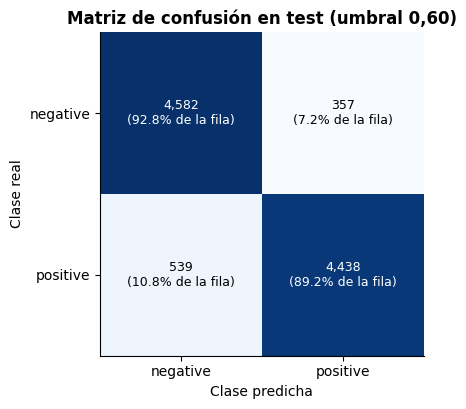

VP 4,438 | FP 357 | FN 539 | VN 4,582


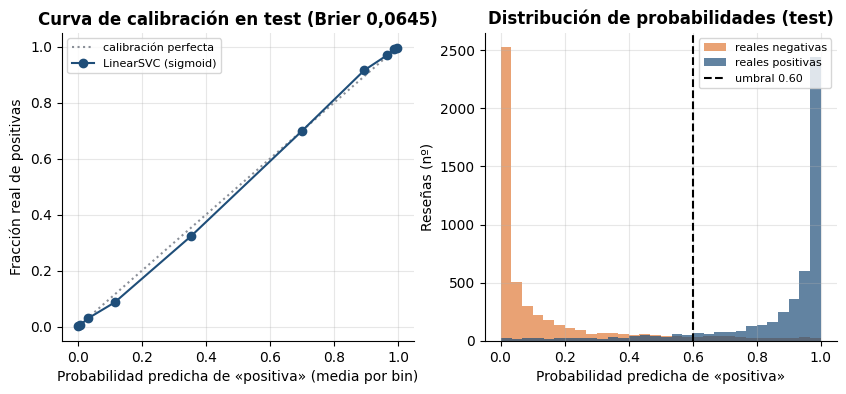

Brier en test (modelo final, sigmoid): 0.06453 [0.06108, 0.06768] | referencia (prior constante): 0.25000


In [13]:
with seccion("8_figuras"):
    cm = confusion_matrix(yte, pred_final_te, labels=[0, 1])
    fig, ax = plt.subplots(figsize=(4.8, 4.2))
    ax.imshow(cm, cmap="Blues")
    ax.grid(False)
    etq = ["negative", "positive"]
    ax.set_xticks([0, 1], etq)
    ax.set_yticks([0, 1], etq)
    ax.set_xlabel("Clase predicha")
    ax.set_ylabel("Clase real")
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{cm[i, j]:,}\n({cm[i, j] / cm[i].sum():.1%} de la fila)",
                    ha="center", va="center",
                    color="white" if cm[i, j] > cm.max() / 2 else "black", fontsize=9)
    ax.set_title(f"Matriz de confusión en test (umbral {UMBRAL:.2f})".replace(".", ","))
    plots.save_fig(fig, "01_matriz_confusion")
    plt.show()
    tn, fp, fn, tp = cm.ravel()
    print(f"VP {tp:,} | FP {fp:,} | FN {fn:,} | VN {tn:,}")

    # Calibración en test del modelo final (probabilidades, antes de aplicar el umbral)
    brier_te = ev.bootstrap_media((p_te - yte) ** 2, N_BOOT, SEED)
    frac, medio = calibration_curve(yte, p_te, n_bins=10, strategy="quantile")
    fig, ax = plt.subplots(1, 2, figsize=(10, 4))
    ax[0].plot([0, 1], [0, 1], ls=":", color=plots.PALETA["neutro"], label="calibración perfecta")
    ax[0].plot(medio, frac, marker="o", color=plots.PALETA["principal"],
               label=f"{FINAL} ({CAL_ELEGIDA})")
    ax[0].set_xlabel("Probabilidad predicha de «positiva» (media por bin)")
    ax[0].set_ylabel("Fracción real de positivas")
    ax[0].set_title(f"Curva de calibración en test (Brier {brier_te['valor']:.4f})".replace(".", ","))
    ax[0].legend(fontsize=8)
    ax[1].hist(p_te[yte == 0], bins=30, alpha=0.7, color=plots.PALETA["enfasis"],
               label="reales negativas")
    ax[1].hist(p_te[yte == 1], bins=30, alpha=0.7, color=plots.PALETA["principal"],
               label="reales positivas")
    ax[1].axvline(UMBRAL, color="black", ls="--", label=f"umbral {UMBRAL:.2f}")
    ax[1].set_xlabel("Probabilidad predicha de «positiva»")
    ax[1].set_ylabel("Reseñas (nº)")
    ax[1].set_title("Distribución de probabilidades (test)")
    ax[1].legend(fontsize=8)
    plots.save_fig(fig, "01_calibracion")
    plt.show()
    brier_base = brier_score_loss(yte, np.full(len(yte), ytr.mean()))
    print(f"Brier en test (modelo final, {CAL_ELEGIDA}): {fmt(brier_te, 5)} | "
          f"referencia (prior constante): {brier_base:.5f}")

**Conclusión técnica:** la matriz en test (umbral 0,60) tiene 357 falsos positivos y 539 falsos
negativos: la asimetría (más FN que FP) es la inducida por `C_FP > C_FN`. El Brier en test es
0,0645 [0,0611; 0,0677] frente a 0,25 de la predicción constante por prior, y la curva de
calibración (decílica) permite usar la probabilidad como medida de confianza; se recomienda
revisarla en producción por posible deriva. La calibración se ajustó en train (validación solo
para elegir método), y el test no intervino.

**Implicación de negocio:** las probabilidades del modelo pueden usarse como nivel de confianza
(p. ej. derivar a revisión humana las reseñas con probabilidad intermedia).

## 9. Costo operativo y comparación de modelos

**Qué:** tabla de costo por modelo (entrenamiento, latencia por reseña, tamaño) y la figura
comparativa. DistilBERT no se entrena aquí (se usa preentrenado): se informa su tiempo de carga y
el tamaño de sus pesos (parámetros × 4 bytes, FP32). **Hardware:** CPU, torch con
`set_num_threads(min(16, nº de núcleos))`, lote de 16 para el transformer; lote de 1 y en lote
completo para los clásicos.

                                        entrenamiento_s  latencia_lote1_ms  latencia_lote_ms  tamano_mb
Regresión Logística                             13.1797             0.6247            0.2723    10.2173
LinearSVC                                       12.6019             0.6496            0.2518    10.2171
Naive Bayes                                     11.4441             2.9939            0.2611    18.3477
LinearSVC + umbral 0.60 (modelo final)              NaN             3.3548            0.7134    21.9267
DistilBERT-SST2                                     NaN            62.5309           62.0117   267.8200

Hardware: 16 núcleos lógicos | DistilBERT: 67 M parámetros; latencia = tokenización + inferencia por reseña (lote 16: muestra de test; lote 1: 50 reseñas de validación)


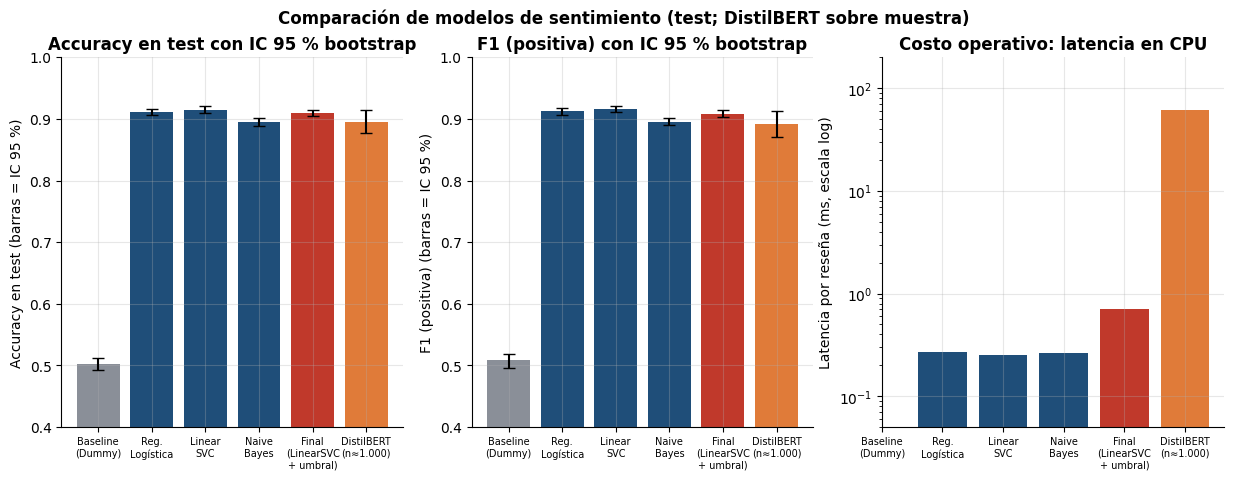

In [14]:
with seccion("9_costo_figura"):
    # Latencia/tamaño del modelo final desplegable (calibrado, 3 pipelines internos).
    lat_f_uno, lat_f_lote = latencias_ms(modelo_prob, Xva)
    tam_final = tamano_mb(modelo_prob)

    # DistilBERT con lote 1 (reseña suelta, como en un servicio en línea): el lote 16 con
    # reseñas ordenadas por longitud minimiza el relleno y lo favorece. Muestra de validación
    # (no se usan etiquetas), 3 reseñas de calentamiento excluidas del tiempo.
    N_UNO_D = 10 if FAST else 50
    textos_uno = list(Xva[sub_va][:N_UNO_D + 3])
    inferir_transformer(tok_d, mod_d, pos_d, textos_uno[:3], lote=1)
    _, seg_uno_d = inferir_transformer(tok_d, mod_d, pos_d, textos_uno[3:], lote=1)
    LAT_D_UNO_MS = seg_uno_d / N_UNO_D * 1000

    costo = {}
    for n, d in MODELOS.items():
        costo[n] = {"entrenamiento_s": d["t_entrena_s"], "busqueda_cv_s": d["t_busqueda_s"],
                    "latencia_lote1_ms": d["lat_uno_ms"], "latencia_lote_ms": d["lat_lote_ms"],
                    "tamano_mb": d["tamano_mb"]}
    costo[NOMBRE_FINAL] = {"entrenamiento_s": None, "busqueda_cv_s": None,
                           "latencia_lote1_ms": lat_f_uno, "latencia_lote_ms": lat_f_lote,
                           "tamano_mb": tam_final}
    costo["DistilBERT-SST2"] = {"entrenamiento_s": None, "busqueda_cv_s": None,
                                "carga_s": TIEMPOS["4_distilbert_carga"],
                                "latencia_lote1_ms": LAT_D_UNO_MS, "latencia_lote_ms": LAT_D_MS,
                                "latencia_lote1_n_resenas": N_UNO_D,
                                "tamano_mb": N_PARAMS_D * 4 / 1e6}
    print(pd.DataFrame(costo).T[["entrenamiento_s", "latencia_lote1_ms", "latencia_lote_ms",
                                 "tamano_mb"]].to_string())
    print(f"\nHardware: {os.cpu_count()} núcleos lógicos | DistilBERT: {N_PARAMS_D / 1e6:.0f} M "
          f"parámetros; latencia = tokenización + inferencia por reseña (lote 16: muestra de "
          f"test; lote 1: {N_UNO_D} reseñas de validación)")

    nombres = ["Baseline (Dummy estratificado)", *MODELOS, NOMBRE_FINAL, "DistilBERT-SST2"]
    etiquetas = ["Baseline\n(Dummy)", "Reg.\nLogística", "Linear\nSVC", "Naive\nBayes",
                 f"Final\n({FINAL}\n+ umbral)", "DistilBERT\n(n≈1.000)"]
    ics = [TEST[n]["ic"] if n in TEST else ic_d_te for n in nombres]
    colores = ([plots.PALETA["neutro"]] + [plots.PALETA["principal"]] * 3
               + [plots.PALETA["referencia"], plots.PALETA["enfasis"]])
    fig, axs = plt.subplots(1, 3, figsize=(15, 4.8))
    for ax, met, titulo in zip(axs[:2], ("accuracy", "f1"), ("Accuracy en test", "F1 (positiva)")):
        v = np.array([ic[met]["valor"] for ic in ics])
        err = np.array([[ic[met]["valor"] - ic[met]["ic95"][0],
                         ic[met]["ic95"][1] - ic[met]["valor"]] for ic in ics]).T
        ax.bar(range(len(v)), v, yerr=err, color=colores, capsize=4)
        ax.set_xticks(range(len(v)), etiquetas, fontsize=7)
        ax.set_ylim(0.4, 1.0)
        ax.set_ylabel(f"{titulo} (barras = IC 95 %)")
        ax.set_title(titulo + " con IC 95 % bootstrap")
    lat = [np.nan, *[costo[n]["latencia_lote_ms"] for n in MODELOS],
           lat_f_lote, LAT_D_MS]
    axs[2].bar(range(len(lat)), lat, color=colores)
    axs[2].set_yscale("log")
    axs[2].set_ylim(0.05, 200)
    axs[2].set_xticks(range(len(lat)), etiquetas, fontsize=7)
    axs[2].set_ylabel("Latencia por reseña (ms, escala log)")
    axs[2].set_title("Costo operativo: latencia en CPU")
    fig.suptitle("Comparación de modelos de sentimiento (test; DistilBERT sobre muestra)",
                 fontweight="bold")
    plots.save_fig(fig, "01_comparacion_modelos")
    plt.show()

### Elección del modelo final: rendimiento frente a costo operativo

| Modelo | Accuracy test [IC 95 %] | Latencia/reseña (lote) | Tamaño | Entrenamiento |
|---|---|---|---|---|
| LinearSVC (final, nativo) | 0,915 [0,910; 0,921] | 0,2-0,4 ms (lote 1: 0,6-1 ms) | ~10 MB | ~11-17 s |
| LinearSVC calibrado + umbral 0,60 (desplegable) | 0,910 [0,904; 0,915] | 0,6-1,0 ms (lote 1: 3-5 ms) | ~22 MB | ~11-17 s por ajuste (3 ajustes en la calibración) |
| Regresión Logística | 0,912 [0,906; 0,917] | 0,2-0,4 ms (lote 1: 0,6-1 ms) | ~10 MB | ~11-17 s |
| DistilBERT-SST2 (muestra n = 1.000) | 0,896 [0,877; 0,914] | 59-66 ms (lote 1: 59-66 ms, n = 50) | ~268 MB | no se entrena |

(La latencia del desplegable es mayor porque la calibración con `cv=3` promedia tres pipelines.
Las latencias se dan como rangos observados en varias ejecuciones (varían según la carga del equipo); los
valores exactos de cada ejecución están en la salida de la celda y en `sentimiento.json`.
La latencia de DistilBERT incluye tokenización y se mide en CPU con lote 16 y con lote 1 (50
reseñas de validación, tras calentamiento); el lote 1 es el relevante para un servicio en línea.)

**Conclusión técnica:** se elige **LinearSVC con calibración sigmoide y umbral 0,60**. Frente a
DistilBERT no hay diferencia significativa en acierto (IC pareado de la diferencia contiene 0,
p = 0,195) y el transformer es ~60-300 veces más lento por reseña en lote (con lote 1, entre 13 y 20 veces más lento que el desplegable y unas 60-100 que el clásico nativo: 59-66 ms frente a 3-5 ms y 0,6-1 ms) y ~12-27 veces mayor en
disco; por tanto no se justifica su costo operativo con esta evidencia. Frente a LR, la ventaja
de LinearSVC en F1 es significativa pero marginal (~0,3 puntos, tanto en validación como en la
comparación pareada descriptiva de test), y se elige por la regla fijada de antemano en la
sección 5, aplicada en validación y sin cambios a posteriori. Reservas: la evaluación de DistilBERT usa n = 1.000 (potencia
limitada para diferencias de ~1 punto); no se afinó (*fine-tuning*) con datos de este dominio,
que probablemente cerraría la brecha a costa de GPU y de más infraestructura, y no se evaluó;
RoBERTa-large no se ejecutó (sin GPU).

**Implicación de negocio:** un modelo clásico de ~10-20 MB acierta ~91 de cada 100 reseñas sin
GPU y sin pagar el costo de un transformer que no demuestra ser mejor.

## 10. Análisis cualitativo de errores del modelo final (test)

**Qué:** las 5 reseñas negativas con mayor probabilidad de «positiva» (falsos positivos más
confiados) y las 5 positivas con menor probabilidad (falsos negativos más confiados), con el
texto truncado a ~300 caracteres. La lectura se hizo **después** de verlos.

In [15]:
err = pd.DataFrame({"texto": Xte, "real": yte, "p_pos": p_te, "pred": pred_final_te})
fp_top = err[(err.real == 0) & (err.pred == 1)].nlargest(5, "p_pos")
fn_top = err[(err.real == 1) & (err.pred == 0)].nsmallest(5, "p_pos")
for titulo, sub in (("FALSOS POSITIVOS (real negativa, predicha positiva)", fp_top),
                    ("FALSOS NEGATIVOS (real positiva, predicha negativa)", fn_top)):
    print(titulo)
    for k, (_, r) in enumerate(sub.iterrows(), 1):
        palabras = len(r.texto.split())
        print(f"  [{k}] P(positiva) = {r.p_pos:.3f} | {palabras} palabras")
        print(textwrap.fill(r.texto[:300] + ("…" if len(r.texto) > 300 else ""),
                            width=100, initial_indent="      ", subsequent_indent="      "))
    print()

FALSOS POSITIVOS (real negativa, predicha positiva)
  [1] P(positiva) = 1.000 | 52 palabras
      this is a great movie. I love the series on tv and so I loved the movie. One of the best
      things in the movie is that Helga finally admits her deepest darkest secret to Arnold!!! that
      was great. i loved it it was pretty funny too. It's a great movie! Doy!!!
  [2] P(positiva) = 0.999 | 134 palabras
      this one of the best celebrity's reality shows a ever saw. we can see the concerts we can see
      the life of Britney, i love the five episodes. i was always being surprised by Britney and the
      subjects of the show i think that some people don't watch the show at all we can how a great
      person she his. sh…
  [3] P(positiva) = 0.998 | 140 palabras
      'Ernest Saves Christmas' is comedian Ernest's Christmas special film. In this film, Ernest has
      to find a successor to Santa Claus in order for Christmas to continue. Along the way, he meets
      a young girl who 

**Lectura de los errores** (hecha tras ver los 10 ejemplos de la ejecución completa; son los de
mayor confianza errónea, por lo que sobrerrepresentan los casos más extremos):

- **FP 1, 2 y 5 (P ≈ 0,99-1,00):** el texto es inequívocamente elogioso («this is a great movie…
  I loved it») y, aun así, la etiqueta es *negative*. Son con alta probabilidad **ruido de
  etiqueta**: el modelo probablemente acierta y el dato falla. FP 4 es una reseña mixta («no es
  una gran película, pero… memorable») y FP 3 una reseña descriptiva con opinión matizada.
- **FN 1, 3 y 4:** reseñas con vocabulario netamente negativo («poor script», «disappointment»,
  «cheesiest movie») etiquetadas como positivas. FN 4 es además un caso de **jerga de género**: en
  el cine de serie B «cheesy/campy» puede ser un elogio, y un modelo léxico lo lee como negativo.
  FN 2 es una **inversión de expectativas** («esperaba odiarla… pero me divirtió»): la palabra
  «HATE» arrastra la predicción. FN 5 es una reseña **larga de citas** (un memorándum de Welles) en
  la que la crítica va dirigida al montaje del estudio, no a la película.
- Patrones: ruido de etiqueta, reseñas mixtas o con inversión narrativa, y reseñas largas donde
  la opinión aparece al final o es una cita. Un modelo bolsa de palabras no captura ironía,
  inversiones ni dependencias largas; no son errores corregibles con más datos del mismo tipo.

**Conclusión técnica:** ~5 de los 10 errores más confiados parecen deberse a etiquetas dudosas;
el resto, a límites típicos de la representación TF-IDF. Esto sugiere un techo de acierto cercano
al observado (~91 %) con este enfoque, y que parte del «error» medido es ruido de etiquetado
(hipótesis a verificar con revisión humana, no demostrada aquí).

**Implicación de negocio:** conviene derivar a revisión humana las reseñas de probabilidad
intermedia y no tratar el acierto del 91 % como un tope por fallo del modelo.

## 11. Métricas finales (JSON) y ficha del modelo

In [16]:
def nativo(o):
    """Convierte tipos de numpy a tipos nativos de Python para json."""
    if isinstance(o, (np.floating, np.integer)):
        return o.item()
    if isinstance(o, np.ndarray):
        return o.tolist()
    raise TypeError(type(o))


ic_final = TEST[NOMBRE_FINAL]["ic"]
cm_d = confusion_matrix(y_sub, pred_d_te, labels=[0, 1]).tolist()
resultado = {
    "modo": MODO,
    "config": {
        "semilla": SEED,
        "particion": {"train": len(Xtr), "validacion": len(Xva), "test": len(Xte),
                      "estratificada": True, "reseñas_totales": N_TOTAL,
                      "sin_duplicados": True},
        "tfidf": {"min_df": 3, "sublinear_tf": True, "dtype": "float32", "lowercase": True},
        "busqueda_cv": {"metodo": "GridSearchCV", "folds": CV_FOLDS, "scoring": "f1",
                        "espacio": {n: {k: [list(x) if isinstance(x, tuple) else x for x in v]
                                        for k, v in g.items()} for n, g in GRIDS.items()}},
        "mejores_hiperparametros": {n: d["params"] for n, d in MODELOS.items()},
        "f1_cv_train": {n: d["f1_cv"] for n, d in MODELOS.items()},
        "n_bootstrap": N_BOOT,
        "modelo_final": {"clasificador": FINAL, "calibracion": CAL_ELEGIDA,
                         "regla_seleccion": "mayor F1 en validación entre los no significati"
                                            "vamente peores (bootstrap pareado); menor latencia"},
        "versiones": {"python": sys.version.split()[0], "scikit-learn": sklearn.__version__,
                      "numpy": np.__version__, "pandas": pd.__version__,
                      "torch": torch.__version__, "transformers": transformers.__version__},
        "hardware": {"nucleos_logicos": os.cpu_count(), "gpu": bool(torch.cuda.is_available())},
    },
    "baseline": {
        "nombre": "DummyClassifier(strategy='stratified')",
        "metricas": {"accuracy": TEST["Baseline (Dummy estratificado)"]["ic"]["accuracy"],
                     "f1": TEST["Baseline (Dummy estratificado)"]["ic"]["f1"]},
        "mejora_modelo_final": {"diferencia_accuracy": par_b["accuracy"],
                                "diferencia_f1": par_b["f1"], "n_test": int(len(yte))},
    },
    "metricas": {
        "accuracy": ic_final["accuracy"],
        "f1": ic_final["f1"],
        "brier": brier_te,
    },
    "umbral": {
        "valor": UMBRAL,
        "justificacion": (
            f"Umbral que minimiza el costo esperado en VALIDACIÓN con C_FP={C_FP:g} (reseña "
            f"negativa clasificada como positiva: queja enmascarada) y C_FN={C_FN:g} (falsa "
            f"alarma revisada por un analista); costo {sel['costo']:.4f} frente a "
            f"{sel['costo_en_0_5']:.4f} con 0,5. Los costos son un supuesto de negocio; la "
            "sensibilidad a otras razones está en 'sensibilidad'."
        ),
        "costos": {"C_FP": C_FP, "C_FN": C_FN},
        "sensibilidad": sensib,
    },
    "modelos_test": {
        n: {"n": int(len(yte)), "accuracy": d["ic"]["accuracy"], "f1": d["ic"]["f1"]}
        for n, d in TEST.items()
    },
    "validacion": {
        "baseline": ic_dummy_va,
        **{n: d["ic_va"] for n, d in MODELOS.items()},
        "brier_por_calibracion": brier_va,
    },
    "distilbert": {
        "modelo": MODELO_DISTIL, "n_test": int(len(sub_te)), "n_validacion": int(len(sub_va)),
        "accuracy": ic_d_te["accuracy"], "f1": ic_d_te["f1"],
        "accuracy_validacion": ic_d_va["accuracy"], "f1_validacion": ic_d_va["f1"],
        "matriz_confusion_test": cm_d, "pct_truncadas_512_test": trunc_te,
        "pct_truncadas_512_validacion": trunc_va, "max_length": 512,
        "modelo_final_misma_muestra": {"accuracy": ic_fin_sub["accuracy"], "f1": ic_fin_sub["f1"]},
        "comparacion_pareada": {"diferencia_accuracy": par_t["accuracy"],
                                "diferencia_f1": par_t["f1"], "mcnemar_exacto": mcn},
        "seleccion_validacion": {"gana_significativamente": bool(DISTIL_GANA),
                                 "diferencia_accuracy": par_d["accuracy"],
                                 "diferencia_f1": par_d["f1"]},
    },
    "roberta_large": {"modelo": MODELO_GRANDE, **INFO_GRANDE},
    "costo_operativo": costo,
    "brier_referencia_prior": float(brier_base),
    "tiempos_seccion_s": TIEMPOS,
}
ruta = RAIZ / "reports" / "metrics" / "sentimiento.json"
ruta.parent.mkdir(parents=True, exist_ok=True)
resultado["linearsvc_vs_lr_test"] = {
    "nota": "descriptivo; la selección se hizo en validación con una regla fijada de antemano",
    "diferencia_accuracy": par_lr["accuracy"], "diferencia_f1": par_lr["f1"], "mcnemar": mcn_lr,
}
ruta.write_text(json.dumps(resultado, indent=2, ensure_ascii=False, default=nativo),
                encoding="utf-8")
print("Guardado: reports/metrics/sentimiento.json")
print(f"Tiempo total de las secciones medidas: {sum(TIEMPOS.values()):.0f} s")
print(TIEMPOS)

Guardado: reports/metrics/sentimiento.json
Tiempo total de las secciones medidas: 294 s
{'1_datos': 5.7, '2_clasicos_cv': 107.7, '3_validacion_clasicos': 16.2, '4_distilbert_carga': 1.8, '4_distilbert_validacion': 30.6, '5_seleccion': 0.2, '6_calibracion_umbral': 43.1, '7_test_clasicos': 15.3, '7_test_distilbert': 62.6, '8_figuras': 0.6, '9_costo_figura': 10.7}


### Ficha del modelo

| Campo | Contenido |
|---|---|
| **Propósito** | Clasificar reseñas de Nile Prime como positivas/negativas para monitorizar la recepción del catálogo. Módulo independiente: las reseñas no tienen título de película, no se vinculan al catálogo. |
| **Modelo** | `Pipeline(TfidfVectorizer(1-2 gramas, min_df=3, sublinear_tf))` + `LinearSVC(C=0,5)`, calibrado con Platt (`CalibratedClassifierCV`, `cv=3`) y umbral 0,60. |
| **Datos** | 49.578 reseñas únicas en inglés (50.000 − 422 duplicados), balanceadas (50,2 % positivas). Split estratificado 70/10/20 con `SEED = 42`. |
| **Métricas (test, n = 9.916, IC 95 % bootstrap, 1.000 remuestreos)** | Accuracy 0,910 [0,904; 0,915]; F1 (positiva) 0,908 [0,903; 0,914]; Brier 0,0645 [0,0611; 0,0677]. Baseline Dummy: 0,503 / 0,508. Con la regla nativa (sin umbral de costo) LinearSVC: 0,915 / 0,916. |
| **Umbral** | 0,60, elegido en validación minimizando el costo esperado con `C_FP:C_FN` = 2:1 (supuesto de negocio: una queja enmascarada cuesta el doble que una falsa alarma). Con 1:1 sería 0,46. |
| **Costo** | Entrenamiento ~11-17 s; latencia 0,2-0,4 ms/reseña en lote y 0,6-1 ms con lote 1 (0,6-1,0 y 3-5 ms el modelo calibrado) en CPU de 16 hilos; ~22 MB serializado. |
| **Alternativa evaluada** | DistilBERT-SST2 sin ajuste: 0,896 [0,877; 0,914] en 1.000 reseñas de test; sin diferencia significativa con el modelo final (p = 0,195), ~60-300 veces más lento (lote 16; ~13-100 con lote 1) y ~268 MB. RoBERTa-large omitido (sin GPU). |
| **Limitaciones y riesgos** | Solo inglés y dominio de reseñas de cine tipo IMDB; deriva léxica con el tiempo (requiere monitorización y reentrenamiento); posible ruido de etiquetas (techo ~91 %); bolsa de palabras ciega a ironía, negaciones largas e inversiones; DistilBERT trunca ~11 % de las reseñas a 512 tokens y su evaluación tiene potencia limitada (n = 1.000); el supuesto de costos 2:1 es una hipótesis que el negocio debe validar; posible sesgo de representación (la fuente es una colección de reseñas públicas, no clientes de Nile Prime). |
| **Uso previsto / no previsto** | Previsto: agregación y alertas sobre el catálogo con revisión humana de casos dudosos. No previsto: decisiones individuales sobre usuarios o sobre texto fuera del dominio. |